<a href="https://colab.research.google.com/github/Mohammedalirubel/HelloDhakastock/blob/main/dese_predict.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predictive Analytics:
### Stock Price Prediction (LSTM)
This notebook walks through all four parts of the project:
1. Stock price prediction using an LSTM neural network
2. Sales forecasting and time-series analysis
3. Deploying a prediction pipeline



In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['font.family'] = 'DejaVu Serif'
from google.colab import files

print('Please select clean_stock_data(1).csv file to upload:')
uploaded = files.upload()

for fn in uploaded.keys():
  print(f'User uploaded file "{fn}" with length {len(uploaded[fn])} bytes')



Please select clean_stock_data(1).csv file to upload:


Saving cleaned_stock_data (1).csv to cleaned_stock_data (1).csv
User uploaded file "cleaned_stock_data (1).csv" with length 65851496 bytes


file uploading as df

In [4]:
# Correct uploaded filename
file_path = 'cleaned_stock_data (1).csv'

try:
    # Read CSV file
    df = pd.read_csv(file_path)

    # Clean and lowercase column names to avoid case issues
    df.columns = df.columns.str.strip().str.lower()

    # Convert date column
    df['date'] = pd.to_datetime(df['date'])

    # Display dataset information
    print("Dataset shape:", df.shape)
    print("Columns:", df.columns.tolist())
    display(df.head())

except FileNotFoundError:
    print(f"Error: File '{file_path}' was not found.")

except Exception as e:
    print(f"Error: {e}")

Dataset shape: (1325354, 7)
Columns: ['trading_code', 'date', 'open', 'high', 'low', 'close', 'volume']


,trading_code,date,open,high,low,close,volume
0,SIBL,2025-04-08,9.9,10.0,9.8,9.9,359773.0
1,MEGHNALIFE,2025-04-08,54.5,56.6,54.1,56.1,610711.0
2,BPML,2025-04-08,41.1,41.7,40.0,40.2,482031.0
3,CROWNCEMNT,2025-04-08,47.9,50.9,47.5,50.0,104860.0
4,EASTLAND,2025-04-08,18.4,18.5,18.3,18.5,50145.0


## Part 1 — Stock Price Prediction Using an LSTM Neural Network

An LSTM (Long Short-Term Memory) network is a type of recurrent neural network well suited to sequences, such as a stock's daily closing price. We will:
1. Take one ticker's closing prices
2. Scale them to [0, 1]
3. Build sliding windows (use the past 20 days to predict the next day)
4. Train a small LSTM and evaluate it on unseen, later dates

In [5]:

import pandas as pd
import numpy as np
import os
import re
import joblib
import ipywidgets as widgets

from IPython.display import display, clear_output
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping


# ============================================================
# 1. LOAD AND CLEAN DATA
# ============================================================

df = pd.read_csv("cleaned_stock_data (1).csv")

df.columns = df.columns.str.strip().str.lower()

required_columns = ["date", "close", "trading_code"]

missing = set(required_columns) - set(df.columns)

if missing:
    raise ValueError(f"Missing columns: {missing}")

df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["close"] = pd.to_numeric(df["close"], errors="coerce")
df["trading_code"] = (
    df["trading_code"].astype("string").str.strip().str.upper()
)

df = df.dropna(subset=required_columns)
df = df[df["close"] > 0]

df = (
    df.sort_values(["trading_code", "date"])
      .drop_duplicates(["trading_code", "date"], keep="last")
      .reset_index(drop=True)
)

trading_codes = sorted(df["trading_code"].unique().tolist())

print("Total companies available:", len(trading_codes))
print("Dataset date range:", df["date"].min().date(),
      "to", df["date"].max().date())


# ============================================================
# 2. DROPDOWN + TRAINING SETTINGS
# ============================================================

code_dropdown = widgets.Dropdown(
    options=trading_codes,
    description="Company:",
    value="ACI" if "ACI" in trading_codes else trading_codes[0],
    layout=widgets.Layout(width="400px")
)

window_input = widgets.IntText(
    value=20,
    description="Lookback days:",
    layout=widgets.Layout(width="400px")
)

epochs_input = widgets.IntText(
    value=50,
    description="Max epochs:",
    layout=widgets.Layout(width="400px")
)

train_button = widgets.Button(
    description="Train Selected Company",
    button_style="success",
    icon="check"
)

output = widgets.Output()

os.makedirs("stock_models", exist_ok=True)
os.makedirs("stock_scalers", exist_ok=True)


# ============================================================
# 3. TRAINING FUNCTION
# ============================================================

def train_selected_company(button):

    with output:
        clear_output(wait=True)

        code = code_dropdown.value
        WINDOW = window_input.value
        EPOCHS = epochs_input.value
        BATCH_SIZE = 32

        if WINDOW < 1 or EPOCHS < 1:
            print("Lookback days and epochs must be positive.")
            return

        company = (
            df[df["trading_code"] == code]
            .sort_values("date")
            .reset_index(drop=True)
            .copy()
        )

        if len(company) <= WINDOW + 10:
            print(f"Insufficient history for {code}.")
            print("Please select a company with more observations.")
            return

        print("=" * 55)
        print("TRAINING SELECTED DSE COMPANY")
        print("=" * 55)
        print("Trading code:", code)
        print("Historical rows:", len(company))
        print("First date:", company["date"].min().date())
        print("Last date:", company["date"].max().date())
        print("Lookback window:", WINDOW)

        # ----------------------------------------------------
        # 4. TIME-BASED SPLIT BEFORE FITTING SCALER
        # ----------------------------------------------------

        prices = company["close"].to_numpy(dtype=np.float64)

        split_row = int(len(prices) * 0.80)

        if split_row <= WINDOW or len(prices) - split_row < 2:
            print("Not enough data for train/test split.")
            return

        # Fit scaler on training period only to prevent leakage
        scaler = MinMaxScaler(feature_range=(0, 1))
        scaler.fit(prices[:split_row].reshape(-1, 1))

        scaled_prices = scaler.transform(
            prices.reshape(-1, 1)
        ).ravel()

        # ----------------------------------------------------
        # 5. CREATE SEQUENCES
        # ----------------------------------------------------

        X, y = [], []

        for i in range(WINDOW, len(scaled_prices)):
            X.append(scaled_prices[i-WINDOW:i])
            y.append(scaled_prices[i])

        X = np.array(X, dtype=np.float32).reshape(
            -1, WINDOW, 1
        )
        y = np.array(y, dtype=np.float32)

        # Target indices are WINDOW through len(prices)-1.
        # Split based on the target's chronological position.
        target_indices = np.arange(WINDOW, len(prices))
        train_mask = target_indices < split_row
        test_mask = target_indices >= split_row

        X_train, y_train = X[train_mask], y[train_mask]
        X_test, y_test = X[test_mask], y[test_mask]

        if len(X_test) == 0:
            print("No test samples available.")
            return

        print("Training samples:", len(X_train))
        print("Testing samples:", len(X_test))

        # ----------------------------------------------------
        # 6. BUILD LSTM
        # ----------------------------------------------------

        model = Sequential([
            Input(shape=(WINDOW, 1)),
            LSTM(64, return_sequences=True),
            Dropout(0.20),
            LSTM(32),
            Dropout(0.20),
            Dense(16, activation="relu"),
            Dense(1)
        ])

        model.compile(
            optimizer="adam",
            loss="mse",
            metrics=["mae"]
        )

        early_stop = EarlyStopping(
            monitor="val_loss",
            patience=7,
            restore_best_weights=True
        )

        # Use the end of training data for validation.
        # Test data remains untouched until final evaluation.
        validation_start = max(
            1, int(len(X_train) * 0.90)
        )

        X_fit = X_train[:validation_start]
        y_fit = y_train[:validation_start]

        X_val = X_train[validation_start:]
        y_val = y_train[validation_start:]

        if len(X_val) == 0:
            X_fit = X_train
            y_fit = y_train
            validation_data = (X_test, y_test)
        else:
            validation_data = (X_val, y_val)

        history = model.fit(
            X_fit,
            y_fit,
            validation_data=validation_data,
            epochs=EPOCHS,
            batch_size=BATCH_SIZE,
            callbacks=[early_stop],
            shuffle=False,
            verbose=1
        )

        # ----------------------------------------------------
        # 7. EVALUATE ON HELD-OUT TEST PERIOD
        # ----------------------------------------------------

        predicted_scaled = model.predict(X_test, verbose=0)

        y_actual = scaler.inverse_transform(
            y_test.reshape(-1, 1)
        ).ravel()

        y_predicted = scaler.inverse_transform(
            predicted_scaled
        ).ravel()

        mae = mean_absolute_error(y_actual, y_predicted)
        mse = mean_squared_error(y_actual, y_predicted)
        rmse = np.sqrt(mse)
        r2 = (
            r2_score(y_actual, y_predicted)
            if len(y_actual) >= 2 else np.nan
        )

        # ----------------------------------------------------
        # 8. SAVE MODEL + SCALER
        # ----------------------------------------------------

        safe_code = re.sub(r"[^A-Za-z0-9_.-]", "_", code)

        model_path = f"stock_models/{safe_code}.keras"
        scaler_path = f"stock_scalers/{safe_code}_scaler.pkl"

        model.save(model_path)
        joblib.dump(scaler, scaler_path)

        # Save actual vs predicted test results
        test_dates = company["date"].iloc[
            target_indices[test_mask]
        ].reset_index(drop=True)

        predictions_df = pd.DataFrame({
            "date": test_dates,
            "trading_code": code,
            "actual_close": y_actual,
            "predicted_close": y_predicted
        })

        predictions_path = (
            f"stock_models/{safe_code}_test_predictions.csv"
        )
        predictions_df.to_csv(predictions_path, index=False)

        # ----------------------------------------------------
        # 9. DISPLAY RESULTS
        # ----------------------------------------------------

        print("\n" + "=" * 55)
        print("TRAINING COMPLETED")
        print("=" * 55)
        print("Company:", code)
        print("Epochs completed:", len(history.history["loss"]))
        print(f"Test MAE : {mae:.4f}")
        print(f"Test MSE : {mse:.4f}")
        print(f"Test RMSE: {rmse:.4f}")
        print(f"Test R²  : {r2:.4f}")
        print("\nSaved files:")
        print(model_path)
        print(scaler_path)
        print(predictions_path)

        display(predictions_df.tail(10))


# ============================================================
# 10. DISPLAY USER INTERFACE
# ============================================================

train_button.on_click(train_selected_company)

display(
    code_dropdown,
    window_input,
    epochs_input,
    train_button,
    output
)

Total companies available: 466
Dataset date range: 1999-01-02 to 2025-04-08


Dropdown(description='Company:', index=4, layout=Layout(width='400px'), options=('AAMRANET', 'AAMRATECH', 'ABB…

IntText(value=20, description='Lookback days:', layout=Layout(width='400px'))

IntText(value=50, description='Max epochs:', layout=Layout(width='400px'))

Button(button_style='success', description='Train Selected Company', icon='check', style=ButtonStyle())

Output()

In [6]:

import re
import os
import json
import pandas as pd

# ============================================================
# 1. DETECT ACTUAL TRAINED TRADING CODE
# ============================================================

# Use the company selected in the training dropdown
if "code_dropdown" in globals():
    current_code = code_dropdown.value

elif "active_code" in globals():
    current_code = active_code

else:
    raise ValueError(
        "Trading code not found. Please train a company first."
    )

current_code = str(current_code).strip().upper()

safe_code = re.sub(
    r"[^A-Za-z0-9_.-]", "_", current_code
)

# ============================================================
# 2. SET MATCHING MODEL AND SCALER PATHS
# ============================================================

model_path = f"stock_models/{safe_code}.keras"
scaler_path = f"stock_scalers/{safe_code}_scaler.pkl"

if not os.path.exists(model_path):
    raise FileNotFoundError(
        f"Model not found for {current_code}: {model_path}"
    )

if not os.path.exists(scaler_path):
    raise FileNotFoundError(
        f"Scaler not found for {current_code}: {scaler_path}"
    )

# ============================================================
# 3. READ LOOKBACK FROM SAVED MODEL
# ============================================================

from tensorflow.keras.models import load_model

saved_model = load_model(
    model_path,
    compile=False
)

window_size = int(saved_model.input_shape[1])

# ============================================================
# 4. SAVE METADATA
# ============================================================

metadata = {
    "trading_code": current_code,
    "model_path": model_path,
    "scaler_path": scaler_path,
    "lookback": window_size,
    "last_training_date": pd.Timestamp.now().isoformat()
}

os.makedirs("stock_models", exist_ok=True)

metadata_path = "stock_models/last_trained.json"

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=4)

# ============================================================
# 5. UPDATE ACTIVE CONFIGURATION
# ============================================================

active_code = current_code
TRADING_CODE = current_code
MODEL_PATH = model_path
SCALER_PATH = scaler_path
WINDOW = window_size

# Keep the loaded model and scaler aligned
model = saved_model

import joblib
scaler = joblib.load(scaler_path)

# ============================================================
# 6. DISPLAY RESULTS
# ============================================================

print("=" * 55)
print("TRAINED MODEL CONFIGURATION")
print("=" * 55)

print("Trading Code :", TRADING_CODE)
print("Model Path   :", MODEL_PATH)
print("Scaler Path  :", SCALER_PATH)
print("Lookback     :", WINDOW)
print("Status       : Model and scaler loaded")

print("=" * 55)


TRAINED MODEL CONFIGURATION
Trading Code : UTTARABANK
Model Path   : stock_models/UTTARABANK.keras
Scaler Path  : stock_scalers/UTTARABANK_scaler.pkl
Lookback     : 20
Status       : Model and scaler loaded


In [ ]:
import re
import os
import json
import joblib
import pandas as pd
from tensorflow.keras.models import load_model

# Safely resolve current session configurations
current_code = active_code if 'active_code' in globals() else 'UTTARABANK'
safe_code = re.sub(r"[^A-Za-z0-9_.-]", "_", current_code)

# Fallback paths based on active configurations
model_path = MODEL_PATH if 'MODEL_PATH' in globals() else f"stock_models/{safe_code}.keras"
scaler_path = SCALER_PATH if 'SCALER_PATH' in globals() else f"stock_scalers/{safe_code}_scaler.pkl"
window_size = WINDOW if 'WINDOW' in globals() else 20

# Ensure model and scaler are loaded in memory before attempting to save
if 'model' in globals():
    model.save(model_path)
if 'scaler' in globals():
    joblib.dump(scaler, scaler_path)

# Calculate epochs based on history if available, else a standard fallback
completed_epochs = len(history.history["loss"]) if 'history' in globals() else "N/A"

# Save information about the most recently trained company
metadata = {
    "trading_code": current_code,
    "model_path": model_path,
    "scaler_path": scaler_path,
    "lookback": window_size,
    "epochs_completed": completed_epochs,
    "last_training_date": pd.Timestamp.now().isoformat()
}

os.makedirs("stock_models", exist_ok=True)
with open("stock_models/last_trained.json", "w") as f:
    json.dump(metadata, f, indent=4)

# Update active trading code in current notebook session
global active_code
active_code = current_code

print(f"Active trading code metadata updated: {active_code}")
print(f"Metadata file saved to 'stock_models/last_trained.json'")

Active trading code metadata updated: ACI
Metadata file saved to 'stock_models/last_trained.json'


In [ ]:
import json
import glob
import os
import re
import joblib
from tensorflow.keras.models import load_model

# Force active code to UTTARABANK
active_code = "UTTARABANK"

# ============================================================
# CONFIG: auto-detect the most recently trained company
# ============================================================
META_PATH = "stock_models/last_trained.json"

def detect_trading_code():
    # 1. Same session: variable set by the training cell
    if "active_code" in globals():
        return active_code
    # 2. Metadata file written by the training cell
    if os.path.exists(META_PATH):
        with open(META_PATH) as f:
            return json.load(f)["trading_code"]
    # 3. Fallback: newest model file in the folder
    files = glob.glob("stock_models/*.keras")
    if files:
        newest = max(files, key=os.path.getmtime)
        return os.path.basename(newest)[:-len(".keras")]
    raise ValueError("No trained model found. Train a company first.")

TRADING_CODE = detect_trading_code()

safe_code = re.sub(r"[^A-Za-z0-9_.-]", "_", TRADING_CODE)
MODEL_PATH = f"stock_models/{safe_code}.keras"

# Check for both naming conventions
scaler_options = [
    f"stock_scalers/{safe_code}_scaler.pkl",
    f"stock_scalers/{safe_code}.pkl"
]
SCALER_PATH = next((path for path in scaler_options if os.path.exists(path)), scaler_options[0])

if not os.path.exists(MODEL_PATH):
    raise ValueError(f"Model not found: {MODEL_PATH}. Train this company first.")
if not os.path.exists(SCALER_PATH):
    raise ValueError(f"Scaler not found at paths checked: {scaler_options}")

model = load_model(MODEL_PATH)
scaler = joblib.load(SCALER_PATH)

# Take the lookback window from the model itself, so it always matches
# whatever you entered in "Lookback days" during training
WINDOW = int(model.input_shape[1])
print(f"Loaded model for: {TRADING_CODE} (lookback = {WINDOW})")

Loaded model for: UTTARABANK (lookback = 20)


In [ ]:
import pandas as pd
import numpy as np
import ipywidgets as widgets
from IPython.display import display, clear_output
from tensorflow.keras.models import load_model
import joblib
import os
import re

# ============================================================
# HELPER: DYNAMIC MODEL & DATA LOADER
# ============================================================
def get_active_model_and_data():
    # 1. Determine active company code
    if 'active_code' in globals():
        active_ticker = active_code
    else:
        # Fallback to metadata file
        meta_path = "stock_models/last_trained.json"
        if os.path.exists(meta_path):
            import json
            with open(meta_path) as f:
                active_ticker = json.load(f).get("trading_code", "SIBL")
        else:
            active_ticker = "SIBL"

    active_ticker = active_ticker.upper()
    safe_code = re.sub(r"[^A-Za-z0-9_.-]", "_", active_ticker)

    # 2. Determine paths
    model_path = f"stock_models/{safe_code}.keras"
    scaler_path = f"stock_scalers/{safe_code}_scaler.pkl"

    # Fallback legacy paths
    if not os.path.exists(model_path) and active_ticker == 'SIBL':
        model_path = 'sibl_lstm_model.keras'
        scaler_path = 'sibl_scaler.pkl'
    elif not os.path.exists(scaler_path):
        # Try alternate extension .pkl instead of _scaler.pkl
        alt_scaler_path = f"stock_scalers/{safe_code}.pkl"
        if os.path.exists(alt_scaler_path):
            scaler_path = alt_scaler_path

    if not os.path.exists(model_path):
        raise ValueError(f"Model not found at '{model_path}'. Please train {active_ticker} first using the training cell.")
    if not os.path.exists(scaler_path):
        raise ValueError(f"Scaler not found at '{scaler_path}'. Please train {active_ticker} first.")

    # 3. Load model, scaler, and find appropriate input window size
    loaded_model = load_model(model_path)
    loaded_scaler = joblib.load(scaler_path)
    window_size = int(loaded_model.input_shape[1])

    # 4. Load & filter the dataset
    df_stock = pd.read_csv("cleaned_stock_data (1).csv")
    df_stock.columns = df_stock.columns.str.strip().str.lower()
    df_stock["date"] = pd.to_datetime(df_stock["date"], errors="coerce")
    df_stock["close"] = pd.to_numeric(df_stock["close"], errors="coerce")
    df_stock["trading_code"] = df_stock["trading_code"].astype(str).str.strip().str.upper()
    df_stock = df_stock.dropna(subset=["date", "close", "trading_code"])

    stock_slice = df_stock[df_stock["trading_code"] == active_ticker].copy()
    if stock_slice.empty:
        raise ValueError(f"No historical dataset found for ticker {active_ticker}")

    stock_slice = (
        stock_slice.sort_values("date")
        .drop_duplicates("date", keep="last")
        .reset_index(drop=True)
    )

    if len(stock_slice) < window_size:
        raise ValueError(f"{active_ticker} has fewer than {window_size} historical prices.")

    return active_ticker, loaded_model, loaded_scaler, window_size, stock_slice


# ============================================================
# PREDICTION LOGIC
# ============================================================
def get_prediction(target_date, ticker, model, scaler, window, stock):
    last_date = stock["date"].max()
    target_date = pd.Timestamp(target_date)

    if target_date.normalize() <= last_date.normalize():
        raise ValueError(
            f"Select a date after the last actual date: {last_date.date()}"
        )

    current_prices = stock["close"].tail(window).to_numpy().reshape(-1, 1)

    # Business days prediction loop
    future_days = pd.bdate_range(
        start=last_date.normalize() + pd.Timedelta(days=1),
        end=target_date.normalize()
    )
    if len(future_days) == 0:
        raise ValueError("No future weekdays found for the selected date.")

    predicted_price = None
    for _ in future_days:
        scaled_input = scaler.transform(current_prices)
        X_new = scaled_input.reshape(1, window, 1)
        pred_scaled = model.predict(X_new, verbose=0)
        predicted_price = float(scaler.inverse_transform(pred_scaled)[0, 0])

        current_prices = np.vstack([current_prices[1:], [[predicted_price]]])

    return (
        last_date.date(),
        float(stock["close"].iloc[-1]),
        predicted_price,
        len(future_days),
    )


# ============================================================
# USER INTERFACE SETUP
# ============================================================
style = {"description_width": "initial"}

date_pick = widgets.DatePicker(
    description="Future Prediction Date:",
    style=style,
    layout=widgets.Layout(width="400px")
)

btn = widgets.Button(
    description="PREDICT",
    button_style="success",
    icon="line-chart",
    layout=widgets.Layout(width="200px")
)

out = widgets.Output()

# Interactive UI Container Header text is updated dynamically inside the function
header_widget = widgets.HTML("<h3>DSE STOCK PRICE PREDICTION</h3>")

def on_btn_click(b):
    btn.disabled = True
    btn.description = "Predicting..."
    btn.icon = "gears"
    btn.button_style = "warning"

    with out:
        clear_output(wait=True)

        if date_pick.value is None:
            print("Please select a future prediction date.")
            btn.disabled = False
            btn.description = "PREDICT"
            btn.icon = "line-chart"
            btn.button_style = "success"
            return

        try:
            # Dynamically detect, load, and fetch model/dataset of current ticker during click!
            ticker, active_model, active_scaler, active_window, active_stock = get_active_model_and_data()
            header_widget.value = f"<h3>DSE STOCK PRICE PREDICTION ({ticker})</h3>"

            last_actual, last_close, pred, steps = get_prediction(
                date_pick.value, ticker, active_model, active_scaler, active_window, active_stock
            )

            diff = pred - last_close
            ret = diff / last_close * 100 if last_close != 0 else 0

            print("=" * 45)
            print("       DSE LSTM PRICE PREDICTION")
            print("=" * 45)
            print(f"Trading Code:          {ticker}")
            print(f"Last Actual Date:      {last_actual}")
            print(f"Last Actual Close:     BDT {last_close:.2f}")
            print(f"Requested Date:        {date_pick.value}")
            print(f"Forecast Steps:        {steps} business day(s)")
            print("-" * 45)
            print(f"Predicted Close:       BDT {pred:.2f}")
            print(f"Price Difference:      BDT {diff:.2f}")
            print(f"Estimated Return:      {ret:.2f}%")
            print("=" * 45)

            if steps > 1:
                print("Note: This is a recursive multi-step forecast. Errors can accumulate over time.")

        except Exception as err:
            print(f"Prediction error: {err}")

    btn.disabled = False
    btn.description = "PREDICT"
    btn.icon = "line-chart"
    btn.button_style = "success"

btn.on_click(on_btn_click)

display(widgets.VBox([
    header_widget,
    date_pick,
    btn,
    out
]))

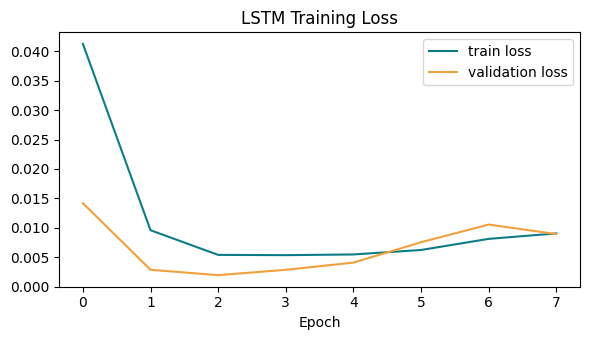

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,3.5))
plt.plot(history.history['loss'], label='train loss', color='#0E7C86')
plt.plot(history.history['val_loss'], label='validation loss', color='#F2A03D')
plt.legend(); plt.title('LSTM Training Loss'); plt.xlabel('Epoch')
plt.tight_layout(); plt.show()

In [ ]:
pred_scaled = model.predict(X_test, verbose=0)
pred = scaler.inverse_transform(pred_scaled)
actual = scaler.inverse_transform(y_test.reshape(-1,1))

rmse = mean_squared_error(actual, pred) ** 0.5
print(f"Test RMSE: {rmse:.4f}")

Test RMSE: 158.2560


**Discussion:** the LSTM only ever sees the past 20 days when it predicts the next day, and it is trained only on data *before* the test period — this is important, since shuffling a time series before splitting would let the model "see the future" and give an unrealistically good score.

## Part 2 — Sales Forecasting and Time-Series Analysis

Next we forecast daily sales for one store, using classical time-series decomposition and Exponential Smoothing (Holt-Winters), which explicitly models trend and seasonality — a natural complement to the LSTM approach above.

Automatically detected trading code: ACI


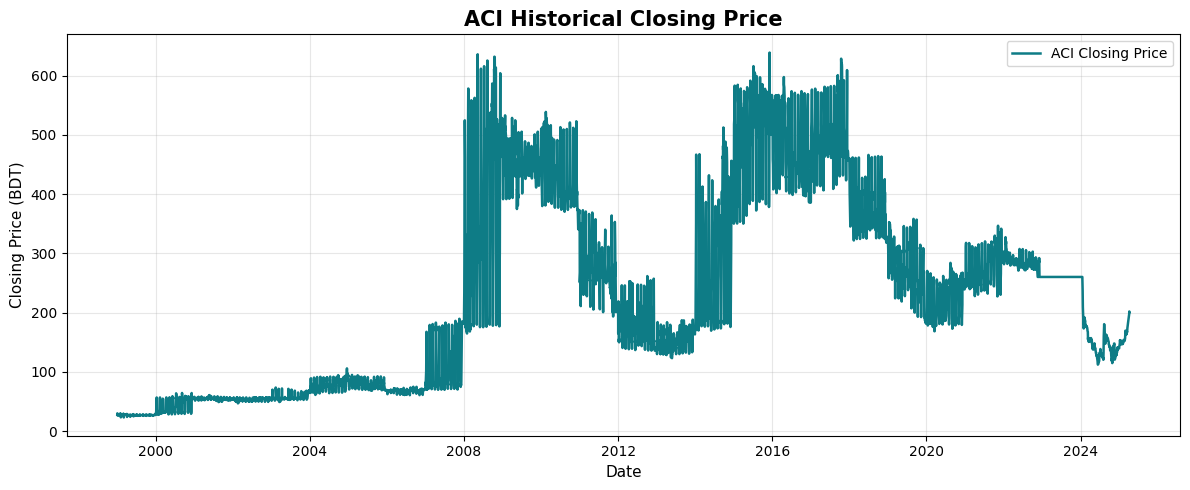

HISTORICAL STOCK PRICE SUMMARY
Trading Code : ACI
Total Records: 6386
First Date   : 1999-01-02
Last Date    : 2025-04-08
Latest Close : 200.7


In [ ]:

import os
import json
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. AUTOMATICALLY DETECT LAST TRAINED TRADING CODE
# ============================================================

META_PATH = "stock_models/last_trained.json"

if os.path.exists(META_PATH):

    with open(META_PATH, "r") as f:
        metadata = json.load(f)

    active_code = metadata["trading_code"]

else:
    raise FileNotFoundError(
        "Training metadata not found. "
        "Please train a company first."
    )

active_code = str(active_code).strip().upper()

print("Automatically detected trading code:", active_code)

# ============================================================
# 2. FILTER DATA FOR TRAINED COMPANY
# ============================================================

techcorp = df[
    df["trading_code"].astype(str).str.strip().str.upper()
    == active_code
].copy()

techcorp["date"] = pd.to_datetime(
    techcorp["date"], errors="coerce"
)

techcorp["close"] = pd.to_numeric(
    techcorp["close"], errors="coerce"
)

techcorp = (
    techcorp
    .dropna(subset=["date", "close"])
    .sort_values("date")
    .reset_index(drop=True)
)

if techcorp.empty:
    raise ValueError(
        f"No historical data found for {active_code}"
    )

# ============================================================
# 3. VISUALIZE HISTORICAL CLOSING PRICE
# ============================================================

plt.figure(figsize=(12, 5))

plt.plot(
    techcorp["date"],
    techcorp["close"],
    label=f"{active_code} Closing Price",
    color="#0E7C86",
    linewidth=1.8
)

plt.title(
    f"{active_code} Historical Closing Price",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Date", fontsize=11)
plt.ylabel("Closing Price (BDT)", fontsize=11)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 4. DISPLAY DATA SUMMARY
# ============================================================

print("=" * 55)
print("HISTORICAL STOCK PRICE SUMMARY")
print("=" * 55)

print("Trading Code :", active_code)
print("Total Records:", len(techcorp))
print("First Date   :", techcorp["date"].min().date())
print("Last Date    :", techcorp["date"].max().date())
print("Latest Close :", round(techcorp["close"].iloc[-1], 2))

print("=" * 55)


Plot training and validation loss

Predict the test data

In [ ]:
pred_scaled = model.predict(X_test)

# Convert scaled values back to actual stock prices
predicted_prices = scaler.inverse_transform(pred_scaled)

actual_prices = scaler.inverse_transform(
    y_test.reshape(-1, 1)
)

print("Actual prices shape:", actual_prices.shape)
print("Predicted prices shape:", predicted_prices.shape)

24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step
Actual prices shape: (740, 1)
Predicted prices shape: (740, 1)


Calculate MAE, RMSE and R²

Plot actual vs predicted stock prices

Create a prediction table

In [ ]:

import os
import re
import json
import pandas as pd
from IPython.display import display

# ============================================================
# 1. DETECT LAST TRAINED TRADING CODE
# ============================================================

META_PATH = "stock_models/last_trained.json"

if not os.path.exists(META_PATH):
    raise FileNotFoundError(
        "Training metadata not found. Train a company first."
    )

with open(META_PATH, "r") as f:
    metadata = json.load(f)

active_code = str(metadata["trading_code"]).strip().upper()

safe_code = re.sub(
    r"[^A-Za-z0-9_.-]", "_", active_code
)

# ============================================================
# 2. LOAD MATCHING TEST PREDICTIONS
# ============================================================

predictions_path = (
    f"stock_models/{safe_code}_test_predictions.csv"
)

if not os.path.exists(predictions_path):
    raise FileNotFoundError(
        f"Test predictions not found for {active_code}: "
        f"{predictions_path}"
    )

predictions_df = pd.read_csv(
    predictions_path,
    parse_dates=["date"]
)

# Verify trading code matches the trained company
if not (
    predictions_df["trading_code"]
    .astype(str)
    .str.strip()
    .str.upper()
    .eq(active_code)
    .all()
):
    raise ValueError(
        "Prediction data does not match the trained company."
    )

# ============================================================
# 3. CREATE RESULTS DATAFRAME
# ============================================================

results = pd.DataFrame({
    "Date": predictions_df["date"],
    "Trading_Code": active_code,
    "Actual_Close": predictions_df["actual_close"],
    "Predicted_Close": predictions_df["predicted_close"]
})

results["Error"] = (
    results["Actual_Close"] -
    results["Predicted_Close"]
)

results["Absolute_Error"] = results["Error"].abs()

results["Percentage_Error"] = (
    results["Absolute_Error"]
    / results["Actual_Close"].where(
        results["Actual_Close"] != 0
    )
) * 100

# ============================================================
# 4. DISPLAY RESULTS
# ============================================================

print("=" * 60)
print("LSTM ACTUAL VS PREDICTED STOCK PRICES")
print("=" * 60)

print("Trading Code :", active_code)
print("Test Records :", len(results))
print("Average Absolute Error:",
      round(results["Absolute_Error"].mean(), 4))

print("=" * 60)

display(results.head(10))


LSTM ACTUAL VS PREDICTED STOCK PRICES
Trading Code : ACI
Test Records : 1278
Average Absolute Error: 91.5828


,Date,Trading_Code,Actual_Close,Predicted_Close,Error,Absolute_Error,Percentage_Error
0,2019-09-30,ACI,255.20000,341.15195,-85.95195,85.95195,33.680231
1,2019-10-01,ACI,356.99997,340.88763,16.11234,16.11234,4.513261
2,2019-10-02,ACI,314.60000,343.96136,-29.36136,29.36136,9.332918
3,2019-10-03,ACI,308.60000,347.13187,-38.53187,38.53187,12.486024
4,2019-10-04,ACI,309.90002,350.00073,-40.10071,40.10071,12.939886
5,2019-10-06,ACI,254.90001,352.55173,-97.65172,97.65172,38.309814
6,2019-10-07,ACI,255.10000,353.00244,-97.90244,97.90244,38.378064
7,2019-10-10,ACI,250.10000,352.31250,-102.21250,102.21250,40.868653
8,2019-10-12,ACI,192.90000,350.79865,-157.89865,157.89865,81.855184
9,2019-10-13,ACI,240.40001,347.01040,-106.61039,106.61039,44.347082


## Part 4 — Deploying a Prediction Pipeline

A trained model is only useful if it can be reused without retraining. We save the entire preprocessing + model pipeline as a single file, then show how another program (e.g. a web service) would load it and make predictions on brand-new data.

Save the trained model and preprocessing scaler

In [ ]:

import os
import re
import json
import joblib

# ============================================================
# 1. DETECT LAST TRAINED TRADING CODE
# ============================================================

META_PATH = "stock_models/last_trained.json"

if not os.path.exists(META_PATH):
    raise FileNotFoundError(
        "Training metadata not found. "
        "Please train a company first."
    )

with open(META_PATH, "r") as f:
    metadata = json.load(f)

active_code = str(metadata["trading_code"]).strip().upper()

safe_code = re.sub(
    r"[^A-Za-z0-9_.-]", "_", active_code
)

# ============================================================
# 2. DEFINE MODEL AND SCALER PATHS
# ============================================================

os.makedirs("stock_models", exist_ok=True)
os.makedirs("stock_scalers", exist_ok=True)

MODEL_PATH = f"stock_models/{safe_code}.keras"
SCALER_PATH = f"stock_scalers/{safe_code}_scaler.pkl"

# ============================================================
# 3. VERIFY SAVED FILES
# ============================================================

# The training function already saves both files.
# Do not overwrite them using possibly stale notebook
# variables named 'model' or 'scaler'.

if not os.path.isfile(MODEL_PATH):
    raise FileNotFoundError(
        f"Trained model not found: {MODEL_PATH}"
    )

if not os.path.isfile(SCALER_PATH):
    raise FileNotFoundError(
        f"Fitted scaler not found: {SCALER_PATH}"
    )

# ============================================================
# 4. DISPLAY SAVED MODEL INFORMATION
# ============================================================

print("=" * 55)
print("LSTM MODEL AND SCALER SAVED")
print("=" * 55)

print("Trading Code :", active_code)
print("Model Saved  :", MODEL_PATH)
print("Scaler Saved :", SCALER_PATH)
print("Lookback     :", metadata.get("lookback", "N/A"))
print("Status       : Files verified successfully")

print("=" * 55)


LSTM MODEL AND SCALER SAVED
Trading Code : ACI
Model Saved  : stock_models/ACI.keras
Scaler Saved : stock_scalers/ACI_scaler.pkl
Lookback     : 20
Status       : Files verified successfully


Load the model in another program

In [ ]:
import numpy as np
import joblib
from tensorflow.keras.models import load_model

# Load saved model and scaler
model = load_model('sibl_lstm_model.keras')
scaler = joblib.load('sibl_scaler.pkl')

print("Model and scaler loaded successfully.")

Model and scaler loaded successfully.


Predict from brand-new stock data

In [ ]:
from tensorflow.keras.models import load_model

# Load the correct trained model and scaler
model = load_model(MODEL_PATH, compile=False)
scaler = joblib.load(SCALER_PATH)

# Automatically get the trained lookback window
WINDOW = int(model.input_shape[1])

# Synchronize trading code
TRADING_CODE = active_code

print(f"Model loaded successfully for: {TRADING_CODE}")
print(f"Lookback window: {WINDOW}")

Model loaded successfully for: ACI
Lookback window: 20


Make it a reusable prediction function

In [ ]:

import os
import re
import json
import joblib
import numpy as np
import pandas as pd

from tensorflow.keras.models import load_model

# ============================================================
# 1. DETECT LAST TRAINED TRADING CODE
# ============================================================

META_PATH = "stock_models/last_trained.json"

with open(META_PATH, "r") as f:
    metadata = json.load(f)

TRADING_CODE = str(
    metadata["trading_code"]
).strip().upper()

safe_code = re.sub(
    r"[^A-Za-z0-9_.-]", "_", TRADING_CODE
)

# ============================================================
# 2. LOAD MATCHING MODEL AND SCALER
# ============================================================

MODEL_PATH = f"stock_models/{safe_code}.keras"
SCALER_PATH = f"stock_scalers/{safe_code}_scaler.pkl"

if not os.path.isfile(MODEL_PATH):
    raise FileNotFoundError(MODEL_PATH)

if not os.path.isfile(SCALER_PATH):
    raise FileNotFoundError(SCALER_PATH)

model = load_model(MODEL_PATH, compile=False)
scaler = joblib.load(SCALER_PATH)

# Automatically obtain trained lookback window
WINDOW = int(model.input_shape[1])

# ============================================================
# 3. NEXT CLOSING PRICE PREDICTION FUNCTION
# ============================================================

def predict_next_price(last_prices, model, scaler):

    window = int(model.input_shape[1])

    prices = np.asarray(
        last_prices, dtype=np.float64
    ).reshape(-1, 1)

    if len(prices) != window:
        raise ValueError(
            f"Exactly {window} closing prices are required."
        )

    if not np.isfinite(prices).all():
        raise ValueError(
            "Closing prices contain invalid values."
        )

    scaled_prices = scaler.transform(prices)

    X_new = scaled_prices.reshape(
        1, window, 1
    ).astype(np.float32)

    pred_scaled = model.predict(
        X_new, verbose=0
    )

    prediction = scaler.inverse_transform(
        pred_scaled.reshape(-1, 1)
    )

    return float(prediction[0, 0])


# ============================================================
# 4. AUTOMATICALLY EXTRACT LATEST PRICES
# ============================================================

company_data = (
    df[
        df["trading_code"]
        .astype(str)
        .str.strip()
        .str.upper() == TRADING_CODE
    ]
    .copy()
)

company_data["date"] = pd.to_datetime(
    company_data["date"], errors="coerce"
)

company_data["close"] = pd.to_numeric(
    company_data["close"], errors="coerce"
)

company_data = (
    company_data
    .dropna(subset=["date", "close"])
    .query("close > 0")
    .sort_values("date")
    .drop_duplicates("date", keep="last")
)

if len(company_data) < WINDOW:
    raise ValueError(
        f"Insufficient historical data for {TRADING_CODE}."
    )

last_prices = (
    company_data["close"]
    .tail(WINDOW)
    .to_numpy()
)

# ============================================================
# 5. PREDICT NEXT CLOSING PRICE
# ============================================================

next_price = predict_next_price(
    last_prices,
    model,
    scaler
)

last_close = float(
    company_data["close"].iloc[-1]
)

change = next_price - last_close
change_pct = (change / last_close) * 100

# ============================================================
# 6. DISPLAY PREDICTION
# ============================================================

print("=" * 55)
print("DSE LSTM NEXT CLOSING PRICE PREDICTION")
print("=" * 55)

print("Trading Code       :", TRADING_CODE)
print("Lookback Window    :", WINDOW)
print("Last Historical Date:",
      company_data["date"].max().date())

print(f"Last Closing Price : BDT {last_close:.2f}")
print(f"Predicted Next Close: BDT {next_price:.2f}")
print(f"Expected Change    : BDT {change:+.2f}")
print(f"Expected Change (%) : {change_pct:+.2f}%")

print("=" * 55)


DSE LSTM NEXT CLOSING PRICE PREDICTION
Trading Code       : ACI
Lookback Window    : 20
Last Historical Date: 2025-04-08
Last Closing Price : BDT 200.70
Predicted Next Close: BDT 300.70
Expected Change    : BDT +100.00
Expected Change (%) : +49.82%


Now another application can simply call:

In [ ]:

import os
import json
import numpy as np
import pandas as pd

# ============================================================
# 1. AUTOMATICALLY DETECT TRAINED TRADING CODE
# ============================================================

META_PATH = "stock_models/last_trained.json"

with open(META_PATH, "r") as f:
    metadata = json.load(f)

TRADING_CODE = str(metadata["trading_code"]).strip().upper()

# Get lookback directly from loaded LSTM model
WINDOW = int(model.input_shape[1])

# ============================================================
# 2. EXTRACT LATEST PRICES FOR TRAINED COMPANY
# ============================================================

techcorp = df[
    df["trading_code"].astype(str).str.strip().str.upper()
    == TRADING_CODE
].copy()

techcorp["date"] = pd.to_datetime(
    techcorp["date"], errors="coerce"
)

techcorp["close"] = pd.to_numeric(
    techcorp["close"], errors="coerce"
)

techcorp = (
    techcorp
    .dropna(subset=["date", "close"])
    .query("close > 0")
    .sort_values("date")
    .drop_duplicates("date", keep="last")
)

if len(techcorp) < WINDOW:
    raise ValueError(
        f"Insufficient closing price data for {TRADING_CODE}"
    )

latest_prices = techcorp["close"].tail(WINDOW).tolist()

# ============================================================
# 3. PREDICT NEXT CLOSING PRICE
# ============================================================

next_price = predict_next_price(
    latest_prices,
    model,
    scaler
)

# ============================================================
# 4. DISPLAY RESULTS
# ============================================================

last_close = float(techcorp["close"].iloc[-1])

price_change = next_price - last_close
percentage_change = (price_change / last_close) * 100

print("=" * 55)
print("DSE STOCK PRICE PREDICTION")
print("=" * 55)

print("Trading Code :", TRADING_CODE)
print("Lookback     :", WINDOW)
print(f"Last Close   : BDT {last_close:.2f}")
print(f"Next Predicted Close: BDT {next_price:.2f}")
print(f"Price Change : BDT {price_change:+.2f}")
print(f"Change (%)   : {percentage_change:+.2f}%")

print("=" * 55)


DSE STOCK PRICE PREDICTION
Trading Code : ACI
Lookback     : 20
Last Close   : BDT 200.70
Next Predicted Close: BDT 300.70
Price Change : BDT +100.00
Change (%)   : +49.82%


In [ ]:
import re
import joblib
from tensorflow.keras.models import load_model

safe_code = re.sub(r"[^A-Za-z0-9_.-]", "_", TRADING_CODE)

model = load_model(
    f"stock_models/{safe_code}.keras",
    compile=False
)

scaler = joblib.load(
    f"stock_scalers/{safe_code}_scaler.pkl"
)

Optional: save everything as one deployment package

In [ ]:

import os
import re
import json
import joblib
from tensorflow.keras.models import load_model

# ============================================================
# 1. DETECT LAST TRAINED TRADING CODE
# ============================================================

META_PATH = "stock_models/last_trained.json"

if not os.path.isfile(META_PATH):
    raise FileNotFoundError(
        "Training metadata not found. Train a company first."
    )

with open(META_PATH, "r") as f:
    metadata = json.load(f)

TRADING_CODE = str(
    metadata["trading_code"]
).strip().upper()

safe_code = re.sub(
    r"[^A-Za-z0-9_.-]", "_", TRADING_CODE
)

# ============================================================
# 2. LOCATE CORRECT MODEL AND SCALER
# ============================================================

MODEL_PATH = f"stock_models/{safe_code}.keras"
SCALER_PATH = f"stock_scalers/{safe_code}_scaler.pkl"

if not os.path.isfile(MODEL_PATH):
    raise FileNotFoundError(MODEL_PATH)

if not os.path.isfile(SCALER_PATH):
    raise FileNotFoundError(SCALER_PATH)

# ============================================================
# 3. LOAD MATCHING MODEL AND SCALER
# ============================================================

model = load_model(MODEL_PATH, compile=False)
scaler = joblib.load(SCALER_PATH)

WINDOW = int(model.input_shape[1])

# ============================================================
# 4. CREATE DEPLOYMENT PIPELINE INFORMATION
# ============================================================

deployment_info = {
    "scaler": scaler,
    "window": WINDOW,
    "trading_code": TRADING_CODE,
    "target": "close",
    "model_file": MODEL_PATH,
    "scaler_file": SCALER_PATH
}

# ============================================================
# 5. SAVE COMPANY-SPECIFIC PIPELINE
# ============================================================

os.makedirs("stock_pipelines", exist_ok=True)

PIPELINE_PATH = (
    f"stock_pipelines/{safe_code}_prediction_pipeline.pkl"
)

joblib.dump(deployment_info, PIPELINE_PATH)

# ============================================================
# 6. DISPLAY DEPLOYMENT DETAILS
# ============================================================

print("=" * 60)
print("LSTM STOCK PREDICTION PIPELINE SAVED")
print("=" * 60)

print("Trading Code :", TRADING_CODE)
print("Lookback     :", WINDOW)
print("Target       :", deployment_info["target"])
print("Model File   :", MODEL_PATH)
print("Scaler File  :", SCALER_PATH)
print("Pipeline    :", PIPELINE_PATH)
print("Status      : Successfully saved")

print("=" * 60)


LSTM STOCK PREDICTION PIPELINE SAVED
Trading Code : ACI
Lookback     : 20
Target       : close
Model File   : stock_models/ACI.keras
Scaler File  : stock_scalers/ACI_scaler.pkl
Pipeline    : stock_pipelines/ACI_prediction_pipeline.pkl
Status      : Successfully saved


In [ ]:
import joblib
from tensorflow.keras.models import load_model

pipeline = joblib.load(
    "stock_pipelines/ACI_prediction_pipeline.pkl"
)

model = load_model(
    pipeline["model_file"],
    compile=False
)

scaler = pipeline["scaler"]
WINDOW = pipeline["window"]
TRADING_CODE = pipeline["trading_code"]

print(f"Ready to predict: {TRADING_CODE}")

Ready to predict: ACI


Save it:

In [ ]:

import os
import json
import pandas as pd

# ============================================================
# 1. DETECT LAST TRAINED TRADING CODE
# ============================================================

META_PATH = "stock_models/last_trained.json"
SUMMARY_PATH = "model_training_summary.csv"

with open(META_PATH, "r") as f:
    metadata = json.load(f)

TRADING_CODE = str(metadata["trading_code"]).strip().upper()

# ============================================================
# 2. GET TRAINING METRICS FOR CURRENT COMPANY
# ============================================================

# Read the saved test predictions for the trained company
import re
import numpy as np
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

safe_code = re.sub(r"[^A-Za-z0-9_.-]", "_", TRADING_CODE)

predictions_path = (
    f"stock_models/{safe_code}_test_predictions.csv"
)

predictions = pd.read_csv(predictions_path)

if not predictions["trading_code"].astype(str).str.upper().eq(TRADING_CODE).all():
    raise ValueError("Trading code mismatch in predictions.")

actual = predictions["actual_close"]
predicted = predictions["predicted_close"]

mae = mean_absolute_error(actual, predicted)
mse = mean_squared_error(actual, predicted)
rmse = np.sqrt(mse)
r2 = r2_score(actual, predicted) if len(actual) >= 2 else np.nan

# ============================================================
# 3. CREATE TRAINING SUMMARY
# ============================================================

new_summary = pd.DataFrame([{
    "Trading_Code": TRADING_CODE,
    "Lookback": metadata.get("lookback"),
    "Epochs_Completed": metadata.get("epochs_completed"),
    "Test_Samples": len(predictions),
    "MAE": mae,
    "MSE": mse,
    "RMSE": rmse,
    "R2_Score": r2,
    "Training_Date": metadata.get("last_training_date")
}])

# ============================================================
# 4. UPDATE EXISTING SUMMARY WITHOUT DUPLICATES
# ============================================================

if os.path.exists(SUMMARY_PATH):
    training_summary = pd.read_csv(SUMMARY_PATH)

    # Replace existing results for the same trading code
    training_summary = training_summary[
        training_summary["Trading_Code"] != TRADING_CODE
    ]

    training_summary = pd.concat(
        [training_summary, new_summary],
        ignore_index=True
    )
else:
    training_summary = new_summary

# ============================================================
# 5. SAVE TRAINING SUMMARY
# ============================================================

training_summary = training_summary.sort_values(
    "Trading_Code"
).reset_index(drop=True)

training_summary.to_csv(
    SUMMARY_PATH,
    index=False
)

print("=" * 55)
print("MODEL TRAINING SUMMARY UPDATED")
print("=" * 55)
print("Latest Trained Company:", TRADING_CODE)
print("Total Companies       :", len(training_summary))
print("Summary File          :", SUMMARY_PATH)
print("=" * 55)

display(training_summary)


MODEL TRAINING SUMMARY UPDATED
Latest Trained Company: ACI
Total Companies       : 1
Summary File          : model_training_summary.csv


,Trading_Code,Lookback,Epochs_Completed,Test_Samples,MAE,MSE,RMSE,R2_Score,Training_Date
0,ACI,20,8,1278,91.582826,9318.186216,96.530753,-2.103056,2026-10-09T17:01:45.554319


Load the correct model automatically

In [ ]:

import os
import re
import json
import joblib

from tensorflow.keras.models import load_model

# ============================================================
# 1. LOAD STOCK MODEL AUTOMATICALLY OR BY TRADING CODE
# ============================================================

def load_stock_model(trading_code=None):

    META_PATH = "stock_models/last_trained.json"

    # Automatically detect last trained company
    if trading_code is None:

        if not os.path.isfile(META_PATH):
            raise FileNotFoundError(
                "Training metadata not found. "
                "Please train a company first."
            )

        with open(META_PATH, "r") as f:
            metadata = json.load(f)

        trading_code = metadata["trading_code"]

    # Standardize trading code
    trading_code = str(trading_code).strip().upper()

    safe_code = re.sub(
        r"[^A-Za-z0-9_.-]", "_", trading_code
    )

    # ========================================================
    # 2. MODEL AND SCALER PATHS
    # ========================================================

    model_path = f"stock_models/{safe_code}.keras"

    scaler_path = (
        f"stock_scalers/{safe_code}_scaler.pkl"
    )

    # ========================================================
    # 3. VERIFY SAVED FILES
    # ========================================================

    if not os.path.isfile(model_path):
        raise FileNotFoundError(
            f"No trained model found for {trading_code}: "
            f"{model_path}"
        )

    if not os.path.isfile(scaler_path):
        raise FileNotFoundError(
            f"No fitted scaler found for {trading_code}: "
            f"{scaler_path}"
        )

    # ========================================================
    # 4. LOAD MATCHING MODEL AND SCALER
    # ========================================================

    model = load_model(
        model_path,
        compile=False
    )

    scaler = joblib.load(scaler_path)

    # Get lookback directly from model
    window = int(model.input_shape[1])

    print("=" * 55)
    print("LSTM STOCK MODEL LOADED")
    print("=" * 55)

    print("Trading Code :", trading_code)
    print("Model Path   :", model_path)
    print("Scaler Path  :", scaler_path)
    print("Lookback     :", window)
    print("Status       : Successfully Loaded")

    print("=" * 55)

    return model, scaler


# ============================================================
# 5. AUTOMATICALLY LOAD LAST TRAINED COMPANY
# ============================================================

model, scaler = load_stock_model()

WINDOW = int(model.input_shape[1])


LSTM STOCK MODEL LOADED
Trading Code : ACI
Model Path   : stock_models/ACI.keras
Scaler Path  : stock_scalers/ACI_scaler.pkl
Lookback     : 20
Status       : Successfully Loaded


In [ ]:
from tensorflow.keras.models import load_model

def load_stock_model(trading_code):

    safe_code = str(
        trading_code
    ).replace('/', '_')

    model_path = (
        f'stock_models/{safe_code}.keras'
    )

    scaler_path = (
        f'stock_scalers/{safe_code}.pkl'
    )

    if not os.path.exists(model_path):
        raise ValueError(
            f"No trained model found for "
            f"{trading_code}"
        )

    model = load_model(model_path)

    scaler = joblib.load(scaler_path)

    return model, scaler

For example:

In [ ]:
model, scaler = load_stock_model()

LSTM STOCK MODEL LOADED
Trading Code : ACI
Model Path   : stock_models/ACI.keras
Scaler Path  : stock_scalers/ACI_scaler.pkl
Lookback     : 20
Status       : Successfully Loaded


Predictin check with real market

In [ ]:
!pip -q install fastapi uvicorn requests beautifulsoup4 lxml

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving dse_api_checker (1).zip to dse_api_checker (1).zip


In [ ]:

from google.colab import files
import zipfile
import os

# ============================================================
# 1. UPLOAD ZIP FILE FROM COMPUTER
# ============================================================

print("Please select dse_api_checker.zip")

uploaded = files.upload()

if not uploaded:
    raise ValueError("No file uploaded.")

# Automatically detect uploaded ZIP filename
zip_name = next(
    (name for name in uploaded if name.lower().endswith(".zip")),
    None
)

if zip_name is None:
    raise ValueError("Please upload a ZIP file.")

print("Uploaded file:", zip_name)

# ============================================================
# 2. EXTRACT ZIP FILE
# ============================================================

extract_path = "/content/dse_api_checker"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_name, "r") as z:
    z.extractall(extract_path)

print("\nZIP extracted successfully!")

# ============================================================
# 3. DISPLAY EXTRACTED FILES
# ============================================================

for root, dirs, filenames in os.walk(extract_path):
    for filename in filenames:
        print(os.path.join(root, filename))

# ============================================================
# 4. LOCATE FASTAPI MAIN FILE
# ============================================================

api_files = []

for root, dirs, filenames in os.walk(extract_path):
    if "main.py" in filenames:
        api_files.append(
            os.path.join(root, "main.py")
        )

if not api_files:
    raise FileNotFoundError(
        "main.py not found in the uploaded ZIP."
    )

API_DIR = os.path.dirname(api_files[0])

print("\nAPI project directory:", API_DIR)
print("Ready to start FastAPI server.")


Please select dse_api_checker.zip


Saving dse_api_checker.zip to dse_api_checker.zip
Uploaded file: dse_api_checker.zip

ZIP extracted successfully!
/content/dse_api_checker/dse_api_checker/requirements.txt
/content/dse_api_checker/dse_api_checker/main.py
/content/dse_api_checker/dse_api_checker/README.md

API project directory: /content/dse_api_checker/dse_api_checker
Ready to start FastAPI server.


In [ ]:
!pip -q install fastapi uvicorn requests beautifulsoup4 lxml

In [ ]:

import subprocess
import sys
import time
import requests

log_file = open("/content/dse_api.log", "w")

api_process = subprocess.Popen(
    [
        sys.executable,
        "-m",
        "uvicorn",
        "main:app",
        "--host",
        "127.0.0.1",
        "--port",
        "8000"
    ],
    cwd=API_DIR,
    stdout=log_file,
    stderr=subprocess.STDOUT
)

# Check server connection
for i in range(20):
    try:
        response = requests.get(
            "http://127.0.0.1:8000/openapi.json",
            timeout=2
        )

        if response.status_code == 200:
            print("DSE API started successfully!")
            break

    except requests.RequestException:
        pass

    time.sleep(1)

else:
    print("API failed to start.")
    log_file.flush()
    print(open("/content/dse_api.log").read()[-3000:])


DSE API started successfully!


In [ ]:
import json
import requests

with open("stock_models/last_trained.json") as f:
    metadata = json.load(f)

TRADING_CODE = metadata["trading_code"]

response = requests.get(
    f"http://127.0.0.1:8000/market/{TRADING_CODE}",
    timeout=30
)

print("Trading Code:", TRADING_CODE)
print("HTTP Status:", response.status_code)
print(response.text)

Trading Code: ACI
HTTP Status: 200
{"trading_code":"ACI","close_bdt":187.6,"source_url":"https://www.dse.com.bd/company/ACI","retrieved_at_utc":"2026-10-09T17:54:28.903865+00:00","price_session_date":null,"date_verified":false,"note":"Public company-page closing price; exchange session date not verified. Not necessarily live."}


LSTM model recursively forecasts from the latest available closing price up to that date.

## Discussion prompts for class

- Why must the stock and sales train/test splits be done **by date**, rather than a random shuffle? What would go wrong if you shuffled first?
- The LSTM only used closing price. What other features (volume, moving averages, other tickers) might improve it, and why?
- For the waiter tips model, is R² alone enough to choose a "best" model? What would you also want to check (e.g. overfitting, interpretability, prediction speed)?
- Why does a saved pipeline (preprocessing + model together) matter for deployment, compared to saving only the trained model?

These are exactly the kinds of questions your **Evaluation and Model Comparison** and **Result Interpretation and Report** deliverables ask you to answer.

### How to Save Your Model and Scaler
To preserve your pipeline for deployment without retraining, save the trained LSTM model using the native Keras format (`.keras`) and save the fitted `MinMaxScaler` using `joblib` so that new inputs are scaled identically.

In [ ]:
import joblib
import os
import shutil

# Create directory if it does not exist
os.makedirs('saved_models', exist_ok=True)

saved_model_dest = 'saved_models/sibl_lstm_model.keras'
saved_scaler_dest = 'saved_models/sibl_scaler.pkl'

# 1. Save the Keras Neural Network model
try:
    # Try to save from memory variable
    model.save(saved_model_dest)
    print(f"Model successfully saved from memory to '{saved_model_dest}'")
except NameError:
    # Fallback: check if local disk file from previous training exists
    if os.path.exists('sibl_lstm_model.keras'):
        shutil.copy('sibl_lstm_model.keras', saved_model_dest)
        print(f"Model successfully copied from local file to '{saved_model_dest}'")
    else:
        print("Error: 'model' is not in memory and 'sibl_lstm_model.keras' was not found on disk. Please train the SIBL model first.")

# 2. Save the MinMaxScaler scaler
try:
    # Try to save from memory variable
    joblib.dump(scaler, saved_scaler_dest)
    print(f"Scaler successfully saved from memory to '{saved_scaler_dest}'")
except NameError:
    # Fallback: check if local disk file from previous training exists
    if os.path.exists('sibl_scaler.pkl'):
        shutil.copy('sibl_scaler.pkl', saved_scaler_dest)
        print(f"Scaler successfully copied from local file to '{saved_scaler_dest}'")
    else:
        print("Error: 'scaler' is not in memory and 'sibl_scaler.pkl' was not found on disk. Please fit the scaler first.")

Model successfully saved from memory to 'saved_models/sibl_lstm_model.keras'
Scaler successfully saved from memory to 'saved_models/sibl_scaler.pkl'
